In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression,SGDClassifier
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit:이진분류함수, softmax:다중분류 함수 0-1숫자로 변환
import numpy as np
from io import StringIO

In [ ]:
# 레드와인, 화이트와인을 분류하는 알고라즘을 구현하시오
# LogisticRegression 사용 - ridge 규제를 사용해서 구현 04
# SGDClassifier 사용 - 반복 300회 해서 구현 05
# 두가지 모델을 사용해서 구현하시오
# 이 확률로 이 와인이다

In [ ]:
# 데이터 전처리
df = pd.read_csv('data/wine.csv')
df
label = df['class'].values # 0레드, 1화이트
data = df[df.columns[:-1]].values
data,label

(array([[ 9.4 ,  1.9 ,  3.51],
        [ 9.8 ,  2.6 ,  3.2 ],
        [ 9.8 ,  2.3 ,  3.26],
        ...,
        [ 9.4 ,  1.2 ,  2.99],
        [12.8 ,  1.1 ,  3.34],
        [11.8 ,  0.8 ,  3.26]], shape=(6497, 3)),
 array([0., 0., 0., ..., 1., 1., 1.], shape=(6497,)))

In [19]:
# 데이터 분류
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)


In [20]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)


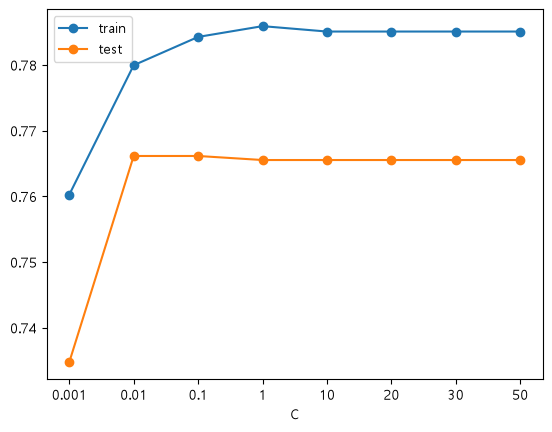

In [64]:
c_list = [0.001, 0.01, 0.1, 1, 10,20,30,50]
train_score = []
test_score = []
for c in c_list:
    lr = LogisticRegression(C=c, max_iter=1000)    # penalty='l2'가 기본값 = Ridge 규제
    lr.fit(train_scaled, train_label)
    train_score.append(lr.score(train_scaled, train_label))
    test_score.append(lr.score(test_scaled, test_label))

x = range(len(c_list))                    # 0,1,2,...,7 → 간격이 같음
plt.plot(x, train_score, label='train', marker='o')
plt.plot(x, test_score, label='test', marker='o')
plt.xticks(x, c_list)                     # 이름은 0.001, 0.01, ..., 50
plt.xlabel('C')
plt.legend()
plt.show()

In [ ]:
# 데이터 학습
lr = LogisticRegression(C=0.01,max_iter=100)
lr.fit(train_scaled,train_label)

# 데이터 예측
# 9.4 ,  1.9 ,  3.51
in_data = '9.4,1.9,3.51'
# in_data = '9.8,2.6,3.2'
in_data = list(map(float,in_data.split(',')))
in_data = ss.transform([in_data])
# result = []
predict = lr.predict(in_data)

if predict[0] =='1.0':
    name ='화이트와인'
else:
    name = '레드와인'
        
predict1 = lr.predict_proba(in_data)
predict2=predict1.max()


print(f'{predict2*100:.2f}% 확률로 {name}이다.')
predict1

array([3.61886228, 0.3919719 , 2.61259091, 2.91654241, 3.38583735])

In [66]:
# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
score,score2

(0.7608784893267652, 0.7329230769230769)